# Tiny NeRF Baseline (Tutorial 10.4) - IFN680 Project 8
Baseline for the comparison in Task 3: a single small MLP that predicts $(\sigma, \mathbf{c})$ from the 3D position only
(no view-dependence) and **uniform (stratified) sampling** along each ray (no hierarchical sampling).

Changes made relative to the tutorial so the comparison with `ExtendedNeRF.ipynb` is controlled:
- identical data split (images 0-99 train, 100+ test), seed, batch size, optimiser, epochs and LR schedule;
- `N_samples = 96` points per ray, matching the 32 + 64 samples the extended model's fine network sees;
- weights saved to `weights/tiny_nerf.pth` and the history to `results/tiny_history.json` for `main_report.ipynb`.

In [1]:
# PyTorch NeRF Implementation
import os
import json
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Reproducibility
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

# Output folders (weights + training histories are read by main_report.ipynb)
os.makedirs('weights', exist_ok=True)
os.makedirs('results', exist_ok=True)

Using device: cuda


# Data - Batching Rays
In this tutorial, we use a small synthetic dataset provided in the file "tiny_nerf_data.npz". This dataset is a simplified version of the data used in the original NeRF paper and contains everything needed to train a minimal model.
- images: [N, H, W, 3] Array with N images of shape 100x100 pixels with three color chanels (RGB).
- A single scalar representing the focal length of the camera in pixels.  This defines the intrinsic calibration matrix as
$$
\mathbf{K} =
\begin{bmatrix}
f & 0 & c_x \\
0 & f & c_y \\
0 & 0 & 1
\end{bmatrix}
$$
where $f$ is the focal length in pixels and $(c_x, c_y)$ is the principal point, here we consider $c_x = 0.5W$ and $c_y = 0.5H$.
- poses: [N, 4, 4] Array of Camera-to-World (C2W) transformation matrices. Each matrix $\mathbf{T}$ describes the camera's position and orientation in 3D space:

$$
\mathbf{T} =
\begin{bmatrix}
R^T & \mathbf{c} \\
\mathbf{0}^\top & 1
\end{bmatrix}
$$

where the top-left $3 \times 3$ block $R^T$ represents the rotation matrix, the top-right $3 \times 1$ vector $\mathbf{c}$ represents the position of the camera in the 3D space,  and the last row enforces homogeneous coordinates. $\mathbf{T}$ transforms a point from the camera's local frame into world coordinates. Its inverse is the world-to-camera (W2C) $\mathbf{T^{-1}} = [R | \mathbf{t}]$ transformation matrix, that defines the Pinhole Camera model as shown in the following figure:

![Title](pinhole_model.webp)

Using this model, a scene view can be formed by projecting 3D points into the image plane using a perspective transformation.


$$s \begin{bmatrix} 
u \\ 
v \\ 
1 
\end{bmatrix} = 
K
[ R \mid \mathbf{t} ]
\begin{bmatrix} 
X \\ 
Y \\ 
Z \\ 
1 
\end{bmatrix}$$


Let's read this dataset

In [2]:
data = np.load('tiny_nerf_data.npz')
images = torch.from_numpy(data['images']).float().to(device)
poses = torch.from_numpy(data['poses']).float().to(device)
focal = float(data['focal'])
H, W = images.shape[1:3]
K = torch.Tensor([[focal, 0, W/2.0], [0, focal, H/2.0], [0, 0, 1]]).float().to(device)
print(f"dataset: Images shape={images.shape}, Poses shape={poses.shape}, Intrinsics={K.shape}")

dataset: Images shape=torch.Size([106, 100, 100, 3]), Poses shape=torch.Size([106, 4, 4]), Intrinsics=torch.Size([3, 3])


Let's also split and visualise our the dataset

training split: torch.Size([100, 100, 100, 3]), training pose shape: torch.Size([100, 4, 4])
test split: torch.Size([6, 100, 100, 3]), test pose shape: torch.Size([6, 4, 4])


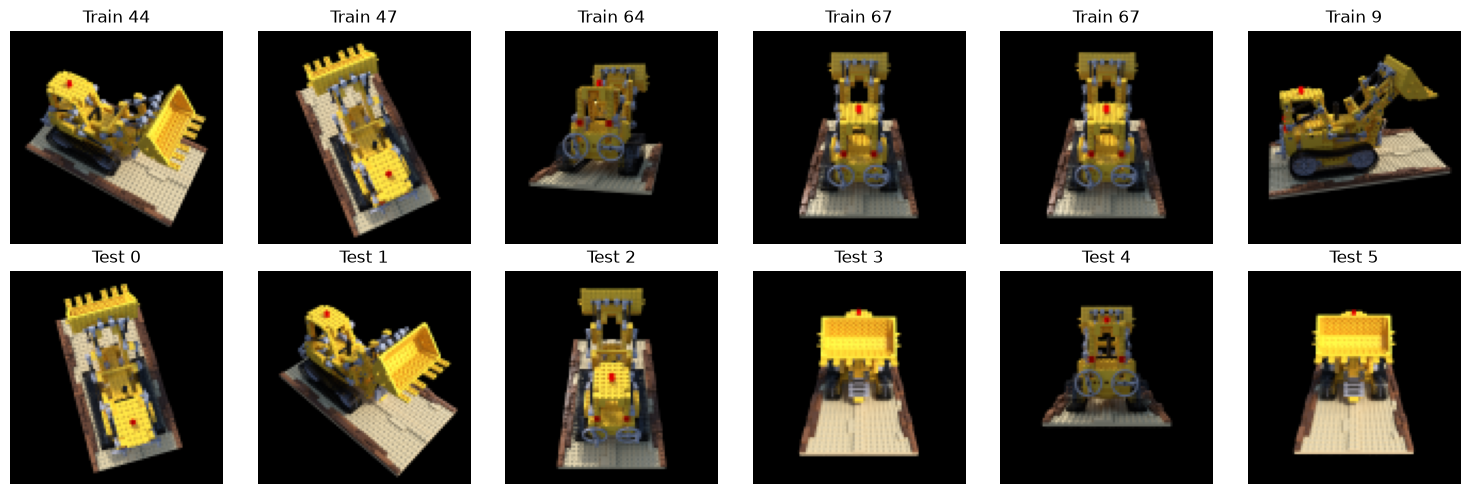

In [3]:
# spliting the dataset into training and test sets
test_images, test_poses = images[100:], poses[100:]
train_images, train_poses = images[:100], poses[:100]
print(f"training split: {train_images.shape}, training pose shape: {train_poses.shape}")
print(f"test split: {test_images.shape}, test pose shape: {test_poses.shape}")

# Create a figure with 2 rows and 6 columns
fig, axes = plt.subplots(2, 6, figsize=(15, 5))

# Plot 6 training images in the first row
for i, sample_idx in enumerate(np.random.randint(0, train_images.shape[0], 6)):    
    axes[0, i].imshow(train_images[sample_idx].cpu().numpy())
    axes[0, i].set_title(f'Train {sample_idx}')
    axes[0, i].axis('off')

# Plot 6 test images in the second row
for i in range(6):
    axes[1, i].imshow(test_images[i].cpu().numpy())
    axes[1, i].set_title(f'Test {i}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

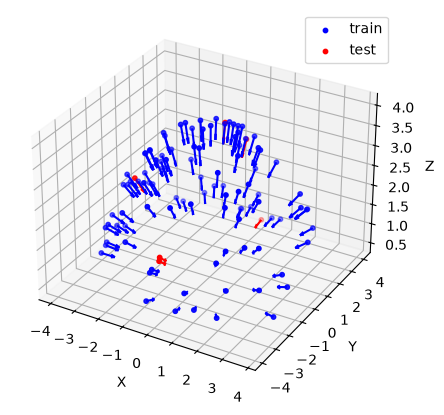

In [4]:
train_centers = train_poses[:, :3, 3].detach().cpu().numpy()
test_centers = test_poses[:, :3, 3].detach().cpu().numpy()

train_dirs = train_poses[:, :3, 2].detach().cpu().numpy()
test_dirs = test_poses[:, :3, 2].detach().cpu().numpy()

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train_centers[:, 0], train_centers[:, 1], train_centers[:, 2], c="blue", s=10, label="train")
ax.scatter(test_centers[:, 0], test_centers[:, 1], test_centers[:, 2], c="red", s=10, label="test")

ax.quiver(
    train_centers[:, 0], train_centers[:, 1], train_centers[:, 2],
    -train_dirs[:, 0], -train_dirs[:, 1], -train_dirs[:, 2],
    length=0.5, color="blue", normalize=True
)
ax.quiver(
    test_centers[:, 0], test_centers[:, 1], test_centers[:, 2],
    -test_dirs[:, 0], -test_dirs[:, 1], -test_dirs[:, 2],
    length=0.5, color="red", normalize=True
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.legend()
plt.show()

NeRF learns a 3D scene by minimizing the error between rendered pixels and ground truth images. We treat our dataset $\mathcal{D}$ of $N$ posed images as a flattened "pool" of $M$ independent pixels, optimizing the network weights $\Theta$:

$$\min_{\Theta} \sum_{k=1}^{M} \| C_\theta(p_k) - I(p_k) \|^2$$

- $C_{\theta}(p)$: Predicted color for pixel $p$.
- $I(p)$: Ground truth RGB color.
    
Predicting color from 2D coordinates alone is ill-posed; we must bridge the gap to 3D by representing each pixel as a **Ray**. Given intrinsics $K$ and camera-to-world pose $[R \mid \mathbf{t}]$, we define the ray $r(t) = \mathbf{o} + t \mathbf{d}$ as:

$$\begin{aligned} \mathbf{o} &= \mathbf{t} \\ \mathbf{d}_{\text{cam}} &= \begin{bmatrix} (u - c_x)/f_x & (v - c_y)/f_y & 1 \end{bmatrix}^\top \\ \mathbf{d} &= R \, \mathbf{d}_{\text{cam}} \\ \end{aligned}$$

Parameters:

- Origin ($\mathbf{o}$): Camera position in world space (\mathbf{t}).
- Direction ($\mathbf{d}$): Local camera vector rotated into world space.
-  $t$ represents the distance (or "time") traveled along the ray starting from the camera origin


To implement our objective function, we need a dataloader that provides batches of **ray origins**, **ray directions**, and **target colors** from our posed images. Let's start by computing all rays given an posed image...
    

In [5]:
def get_rays(K, c2w, H, W):
    """
    TODO: Get ray origin, direction to each image pixels based on camera pose
    """
    # 1. Create pixel grid, x first
    i, j = torch.meshgrid(
        torch.arange(W, dtype=torch.float32, device=c2w.device),
        torch.arange(H, dtype=torch.float32, device=c2w.device),
        indexing='xy'
    )

    # 2. Get directions in camera coordinates
    # We use the explicit K components: (u - cx)/fx, (v - cy)/fy
    # NeRF typically uses -1 for the z-axis (looking "into" the screen)
    dirs = torch.stack([
        (i - K[0, 2]) / K[0, 0],
        -(j - K[1, 2]) / K[1, 1], # Negated to flip y-axis for standard NeRF orientation
        -torch.ones_like(i)
    ], dim=-1)

    # 3. Transform directions to world space
    # (H, W, 3) @ (3, 3) -> (H, W, 3)
    rays_d = dirs @ c2w[:3, :3].T
    
    # 4. Origin is the translation vector of the camera-to-world matrix
    rays_o = c2w[:3, -1].expand(rays_d.shape)
    return rays_o, rays_d

rays_o_i, rays_d_i = get_rays(K, train_poses[0], H, W)
rays_o_j, rays_d_j = get_rays(K, train_poses[10], H, W)
print(f"rays_o_i shape: {rays_o_i.shape}, rays_d_i shape: {rays_d_i.shape}")
print(f"rays_o_j shape: {rays_o_j.shape}, rays_d_j shape: {rays_d_j.shape}")

rays_o_i shape: torch.Size([100, 100, 3]), rays_d_i shape: torch.Size([100, 100, 3])
rays_o_j shape: torch.Size([100, 100, 3]), rays_d_j shape: torch.Size([100, 100, 3])


Now that, we know how to compute rays let's create our **NeRFDataset** and **Dataloader**...

In [6]:
class NeRFDataset(torch.utils.data.Dataset):
    def __init__(self, images, poses, intrinsic):
        """
        images: (N_images, H, W, 3)
        poses: (N_images, 4, 4)
        """
        # class attributes
        self.images, self.poses, self.intrinsic = images, poses, intrinsic        
        self.H, self.W = images.shape[1], images.shape[2]
        self.all_rays_o, self.all_rays_d, self.all_rays_rgbs = [], [], [] 

        # compute all rays
        for i in range(len(images)):
            rays_o, rays_d = get_rays(self.intrinsic, self.poses[i], self.H, self.W)
            self.all_rays_o.append(rays_o.reshape(-1, 3))            
            self.all_rays_d.append(rays_d.reshape(-1, 3))            
            self.all_rays_rgbs.append(images[i].reshape(-1, 3))

        # Concatenate all rays from all images
        self.all_rays_o = torch.cat(self.all_rays_o, dim=0)
        self.all_rays_d = torch.cat(self.all_rays_d, dim=0)
        self.all_rays_rgbs = torch.cat(self.all_rays_rgbs, dim=0)

    def __len__(self):
        return len(self.all_rays_o)

    def __getitem__(self, idx):
        return (self.all_rays_o[idx], self.all_rays_d[idx], self.all_rays_rgbs[idx])

train_dataloader = torch.utils.data.DataLoader(NeRFDataset(train_images, train_poses, K), batch_size=1024, shuffle=True)

Let's visualize some sampled rays...

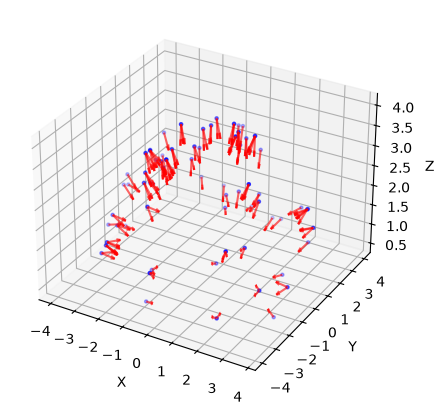

In [7]:
rays_o, rays_d, rays_rgb = next(iter(train_dataloader))
n = min(128, rays_o.shape[0])
rays_o = rays_o[:n].cpu().numpy()
rays_d = rays_d[:n].cpu().numpy()

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(rays_o[:, 0], rays_o[:, 1], rays_o[:, 2], s=5, c="blue", alpha=0.6)
ax.quiver(
    rays_o[:, 0], rays_o[:, 1], rays_o[:, 2],
    rays_d[:, 0], rays_d[:, 1], rays_d[:, 2],
    length=0.5, normalize=True, color="red", alpha=0.6
)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

# Model - Neural Scene Representation (Tiny NeRF)

The Tiny NeRF simplifies the full model in two ways:
- **No view-dependence**: the MLP only receives $\gamma(\mathbf{x})$, so the colour of a point is the same from every angle (matte).
- **Simplified MLP**: three hidden layers of width 128 instead of the 8-layer, 256-wide network with skip connections.

$$F_\theta : \gamma(\mathbf{x}) \mapsto (\sigma, \mathbf{c})$$

In [8]:
class PositionalEncoding(torch.nn.Module):
    """
    Positional encoding module
    """
    def __init__(self, L_embed=6):
        super(PositionalEncoding, self).__init__()
        # frequency bands used
        self.L_embed = L_embed
        self.bands = (2.0 ** torch.arange(L_embed, dtype=torch.float32).to(device)) * torch.pi
        self.bands = self.bands.view(1, L_embed, 1)  # shape (1, L_embed, 1)

    def forward(self, x):
        x_scaled = x.unsqueeze(-2) * self.bands  # shape (N, L, D)
        sin_cos = torch.cat([torch.sin(x_scaled), torch.cos(x_scaled)], dim=-2) # shape (N, 2*L, D)
        sin_cos = sin_cos.flatten(start_dim=-2)  # (N, 2*L*D)
        encoded = torch.cat([x, sin_cos], dim=-1)  # (N, D + 2*L*D)
        return encoded


class TinyNeRF(torch.nn.Module):
    """
    Tiny NeRF baseline (Tutorial 10.4): a single small MLP that maps the encoded 3D
    position gamma(x) to (sigma, rgb). The viewing direction is ignored -> matte renderer.
    The `dir` argument is accepted only so both models share the same interface.
    """
    def __init__(self, filter_size=128, L_embed=6):
        super(TinyNeRF, self).__init__()
        self.positional_encoding = PositionalEncoding(L_embed)
        x_dim = 3 + 3 * 2 * L_embed
        self.layer1 = torch.nn.Linear(x_dim, filter_size)
        self.layer2 = torch.nn.Linear(filter_size, filter_size)
        self.layer3 = torch.nn.Linear(filter_size, filter_size)
        self.output_layer = torch.nn.Linear(filter_size, 4)

    def forward(self, x, dir=None):
        h = F.relu(self.layer1(self.positional_encoding(x)))
        h = F.relu(self.layer2(h))
        h = F.relu(self.layer3(h))
        out = self.output_layer(h)
        sigma = F.relu(out[..., :1])          # density >= 0
        rgb = torch.sigmoid(out[..., 1:])     # colour in [0, 1]
        return torch.cat([sigma, rgb], dim=-1)


nerf = TinyNeRF(filter_size=128, L_embed=6).to(device)
print(nerf)

TinyNeRF(
  (positional_encoding): PositionalEncoding()
  (layer1): Linear(in_features=39, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=128, bias=True)
  (output_layer): Linear(in_features=128, out_features=4, bias=True)
)


# Inference - Volume Rendering

At inference we need to use our neural radiance field to render the color of a ray (or pixel). NeRF simulates how light travels through the scene and reaches the camera.  This is implemented via **volume rendering**. The color of a ray $r(t)$ is computed as an integral of the radiance field along the ray:

$$
C_\theta(p) = C_\theta(r) = \int_{t_{\text{near}}}^{t_{\text{far}}} 
T(t)\, \sigma(r(t))\, \mathbf{c}(r(t), \mathbf{d}) \, dt,
$$

where:

- $\sigma(r(t))$ = volume density (geometry)  
- $\mathbf{c}(r(t), \mathbf{d})$ = RGB color (appearance)  
- $T(t)$ = transmittance, the probability that light travels from $t_{\text{near}}$ to $t$ without being absorbed.



In practice, we approximate it by sampling $N$ points $t_1, \dots, t_N$ along the ray. For each sample $i$, we define:

- $\mathbf{x}_i = r(t_i)$: The 3D position of the sample.
- $\sigma_i, \mathbf{c}_i$: The density and color predicted by the MLP at that position.
- $\delta_i = t_{i+1}-t_i$: The distance between adjacent samples.

We then convert these densities into opacities ($\alpha_i$) and calculate the accumulated transmittance 
($T_i$):$$\alpha_i = 1 - \exp(-\sigma_i \delta_i), \quad T_i = \prod_{j=1}^{i-1} (1-\alpha_j)$$

The final pixel color is the weighted sum of all colors along the ray:

$$C_\theta(r) \approx \sum_{i=1}^{N} T_i \alpha_i \mathbf{c}_i$$

Here, $T_i \alpha_i$ represents the visibility weight. It describes how much a specific 3D point contributes to the 2D pixel, accounting for both its own density and how much it is "blocked" by points in front of it. This formulation is fully differentiable, allowing us to backpropagate the loss from the 2D image back to the 3D density field. 

Let's code our volume rendering ...


In [9]:
def volume_rendering(sigma, rgb, t_vals):
    # Calculate distance between samples (delta)
    # t_vals shape: [N_rays, N_samples]
    deltas = t_vals[..., 1:] - t_vals[..., :-1]
    
    # Append a large value (1e10) for the last interval
    dist_shape = list(deltas.shape[:-1]) + [1]
    last_dist = torch.full(dist_shape, 1e10, device=sigma.device)
    deltas = torch.cat([deltas, last_dist], dim=-1)

    # alpha = 1.0 - exp(-sigma * delta)
    # sigma must be non-negative (usually ensured by ReLU in the MLP)
    alpha = 1.0 - torch.exp(-sigma * deltas)
    
    # Transmittance T_i = product of (1 - alpha_j) for j < i
    # We use cumprod on (1-alpha) shifted by one position
    # prepend 1.0 because T_1 is always 1.0
    shifted_transmittance = torch.cat([torch.ones_like(alpha[..., :1]), 1.0 - alpha + 1e-10], dim=-1)
    T = torch.cumprod(shifted_transmittance, dim=-1)[..., :-1]

    # color blending
    weights = alpha * T # [N_rays, N_samples]
    rgb_map = torch.sum(weights[..., None] * rgb, dim=-2) # [N_rays, 3]
    
    return rgb_map, weights


### Uniform (stratified) sampling
The Tiny NeRF divides $[t_n, t_f]$ into $N$ equal bins and draws one point per bin (jittered during training,
bin edges at test time). Every ray is evaluated at the same depths whether or not they contain geometry.

In [10]:
def stratified_samples(N_rays, near, far, N_samples, rand, device):
    """Evenly spaced depths in [near, far]; with rand=True one jittered sample per bin."""
    t_vals = torch.linspace(near, far, N_samples, device=device).expand(N_rays, N_samples)
    if rand:
        # Add jitter: sample uniformly inside each bin [lower_i, upper_i]
        mids = 0.5 * (t_vals[..., 1:] + t_vals[..., :-1])
        upper = torch.cat([mids, t_vals[..., -1:]], dim=-1)
        lower = torch.cat([t_vals[..., :1], mids], dim=-1)
        t_vals = lower + (upper - lower) * torch.rand_like(t_vals)
    return t_vals                                                  # [N_rays, N_samples]


def query_network(network, rays_o, rays_d, t_vals):
    """Evaluate a radiance field at r(t) = o + t d for every depth in t_vals."""
    pts = rays_o[:, None, :] + rays_d[:, None, :] * t_vals[..., :, None]   # [N_rays, N_s, 3]
    dirs = rays_d[:, None, :].expand_as(pts)                                # [N_rays, N_s, 3]
    raw = network(pts, dirs)                                                # [N_rays, N_s, 4]
    return raw[..., 0], raw[..., 1:]                                        # sigma, rgb


def render_rays_uniform(network, rays_o, rays_d, near, far, N_samples, rand=False, return_extras=False):
    """Tiny NeRF rendering: one network, stratified (uniform) samples only."""
    batch_shape = rays_o.shape[:-1]
    rays_o, rays_d = rays_o.reshape(-1, 3), rays_d.reshape(-1, 3)
    t_vals = stratified_samples(rays_o.shape[0], near, far, N_samples, rand, rays_o.device)
    sigma, rgb = query_network(network, rays_o, rays_d, t_vals)
    rgb_map, weights = volume_rendering(sigma, rgb, t_vals)
    rgb_map = rgb_map.reshape(*batch_shape, 3)
    if return_extras:
        extras = {'t': t_vals, 'weights': weights,
                  'depth': torch.sum(weights * t_vals, -1).reshape(batch_shape),
                  'acc': torch.sum(weights, -1).reshape(batch_shape)}
        return rgb_map, extras
    return rgb_map


def render_image(network, rays_o, rays_d, near, far, N_samples, chunk=4096):
    """Render a full image in chunks of rays (deterministic sampling)."""
    H_, W_ = rays_o.shape[:2]
    rays_o, rays_d = rays_o.reshape(-1, 3), rays_d.reshape(-1, 3)
    out = [render_rays_uniform(network, rays_o[i:i+chunk], rays_d[i:i+chunk], near, far, N_samples, rand=False)
           for i in range(0, rays_o.shape[0], chunk)]
    return torch.cat(out).reshape(H_, W_, 3)

# NeRF Training Procedure (Tiny NeRF)
Same loop as the extended model, but with a single network and a single photometric loss
$\mathcal{L} = \sum_{\mathbf{r}} \| C_\theta(\mathbf{r}) - I(\mathbf{r}) \|^2$.

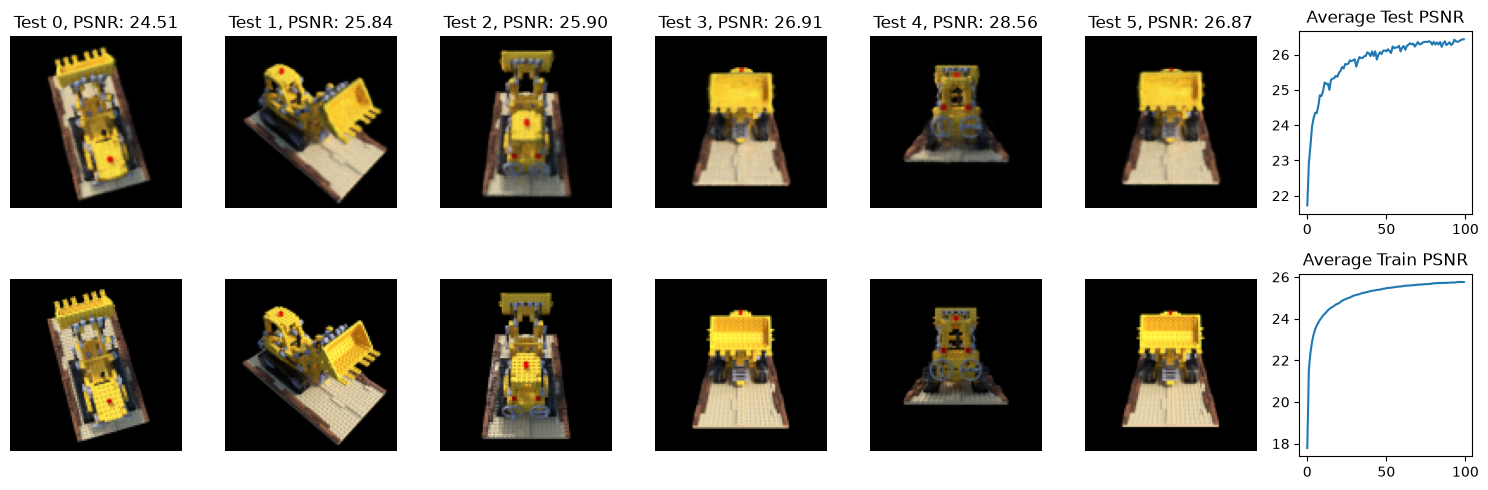

epoch 100/100  train PSNR 25.76  test PSNR 26.43  (23.4s)


In [11]:
# Initialize model and optimizer
model = TinyNeRF(filter_size=128, L_embed=6).to(device)
optimizer = optim.Adam(model.parameters(), lr=5e-4)

# training parameters
N_epochs = 100
N_samples = 96          # = N_c + N_f of the extended model

USE_LR_DECAY = True     # same schedule as ExtendedNeRF.ipynb
scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.1 ** (1.0 / N_epochs)) if USE_LR_DECAY else None

train_psnrs, test_psnrs, epoch_times = [], [], []
for epoch in range(N_epochs):
    t0 = time.time()
    model.train()

    # train
    avg_psnr, ray_count = 0.0, 0
    for rays_o, rays_d, rays_rgb in train_dataloader:
        optimizer.zero_grad()
        rgb = render_rays_uniform(model, rays_o, rays_d, near=2., far=6., N_samples=N_samples, rand=True)
        loss = F.mse_loss(rgb, rays_rgb)
        loss.backward()
        optimizer.step()
        avg_psnr += (-10. * torch.log10(loss)).cpu().item()
        ray_count += 1

    if scheduler is not None:
        scheduler.step()
    epoch_times.append(time.time() - t0)
    train_psnrs.append(avg_psnr / ray_count)

    # test
    model.eval()
    with torch.no_grad():
        clear_output(wait=True)
        fig, axes = plt.subplots(2, 7, figsize=(15, 5))
        avg_psnr = 0.0
        for test_idx in range(len(test_images)):
            testimg, testpose = test_images[test_idx], test_poses[test_idx]
            rays_o, rays_d = get_rays(K, testpose, H, W)
            rgb = render_image(model, rays_o, rays_d, near=2., far=6., N_samples=N_samples)
            test_loss = F.mse_loss(rgb, testimg)
            psnr = (-10. * torch.log10(test_loss)).cpu().item()
            avg_psnr += psnr
            axes[0,test_idx].set_title(f"Test {test_idx}, PSNR: {psnr:.2f}");
            axes[0,test_idx].imshow(rgb.clamp(0, 1).cpu().numpy()); axes[0, test_idx].axis('off');
            axes[1,test_idx].imshow(testimg.cpu().numpy()); axes[1, test_idx].axis('off');

        test_psnrs.append(avg_psnr / len(test_images))
        axes[0,6].plot(test_psnrs, label='Test')
        axes[0,6].set_title('Average Test PSNR')
        axes[1,6].plot(train_psnrs, label='Train')
        axes[1,6].set_title('Average Train PSNR')
        plt.tight_layout()
        plt.show()
    print(f"epoch {epoch+1}/{N_epochs}  train PSNR {train_psnrs[-1]:.2f}  test PSNR {test_psnrs[-1]:.2f}  ({epoch_times[-1]:.1f}s)")

## Save trained weights and training history

In [12]:
torch.save({'model': model.state_dict(),
            'config': {'filter_size': 128, 'L_embed': 6, 'N_samples': N_samples, 'near': 2.0, 'far': 6.0}},
           'weights/tiny_nerf.pth')

with open('results/tiny_history.json', 'w') as fh:
    json.dump({'train_psnrs': train_psnrs, 'test_psnrs': test_psnrs, 'epoch_times': epoch_times,
               'N_epochs': N_epochs, 'N_samples': N_samples, 'lr_decay': USE_LR_DECAY, 'seed': SEED}, fh)
print(f"saved | final test PSNR {test_psnrs[-1]:.2f} dB | mean epoch time {np.mean(epoch_times):.1f}s")

saved | final test PSNR 26.43 dB | mean epoch time 23.4s


## Interactive Visualization: Novel View Synthesis
Place a virtual camera on a sphere around the object and render it with the trained Tiny NeRF.

In [13]:
%matplotlib inline
from ipywidgets import interactive, widgets


trans_t = lambda t: torch.tensor([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, t],
    [0, 0, 0, 1],
], dtype=torch.float32)

# Rotation about x-axis (phi)
rot_phi = lambda phi: torch.tensor([
    [1, 0, 0, 0],
    [0, torch.cos(phi), -torch.sin(phi), 0],
    [0, torch.sin(phi),  torch.cos(phi), 0],
    [0, 0, 0, 1],
], dtype=torch.float32)

# Rotation about y-axis (theta)
rot_theta = lambda th: torch.tensor([
    [torch.cos(th), 0, -torch.sin(th), 0],
    [0, 1, 0, 0],
    [torch.sin(th), 0,  torch.cos(th), 0],
    [0, 0, 0, 1],
], dtype=torch.float32)

def pose_spherical(theta, phi, radius):
    c2w = trans_t(radius)
    c2w = rot_phi(torch.tensor(phi / 180. * np.pi)) @ c2w
    c2w = rot_theta(torch.tensor(theta / 180. * np.pi)) @ c2w
    c2w = torch.tensor([
        [-1, 0, 0, 0],
        [ 0, 0, 1, 0],
        [ 0, 1, 0, 0],
        [ 0, 0, 0, 1],
    ], dtype=torch.float32) @ c2w
    return c2w.to(device)

def f(**kwargs):
    c2w = pose_spherical(**kwargs)
    rays_o, rays_d = get_rays(K, c2w[:3, :4], H, W)
    with torch.no_grad():
        rgb = render_image(model, rays_o, rays_d, near=2., far=6., N_samples=N_samples)
    img = rgb.detach().cpu().numpy()
    img = np.clip(img, 0, 1)

    
    plt.figure(2, figsize=(20, 6))
    plt.imshow(img)
    plt.show()

sldr = lambda v, mi, ma: widgets.FloatSlider(
    value=v,
    min=mi,
    max=ma,
    step=0.01,
)

names = [
    ['theta', [100., 0., 360.]],
    ['phi', [-30., -90., 0.]],
    ['radius', [4., 3., 5.]],
]

interactive_plot = interactive(f, **{s[0]: sldr(*s[1]) for s in names})
output = interactive_plot.children[-1]
output.layout.height = '350px'
interactive_plot

interactive(children=(FloatSlider(value=100.0, description='theta', max=360.0, step=0.01), FloatSlider(value=-…